# Chapter 0, Setup: Everything You Need, Nothing You Don't

Welcome! This project tells one story, in plain words, with real numbers: **how Lula trailed in the first round of Brazil's 2026 presidential election and won the runoff, and what the data can, and cannot, say about the fraud claims that followed.**

No background in politics, statistics, or code is needed. Every concept is explained before it is used, and every chart is computed from a public dataset listed below, nothing is hand-drawn or invented.

> **About the dispute, up front.** Flávio Bolsonaro refused to concede after the runoff and alleged fraud (see Chapter 5 for the exact claim, with attribution). The electoral court (TSE), foreign governments, and his own party (PL) accepted the result. **The TSE count is the source of truth in this project.** Wherever results are shown, the contestation is labelled, it is never hidden, and it is never treated, by itself, as proof of fraud *or* proof of cleanliness. Chapter 5 tests only what aggregate data can actually test, and says plainly what it cannot test.

## The chapters

| Notebook | Chapter | What you will learn |
|---|---|---|
| `00_setup.ipynb` | Setup (this one) | Project structure, tools, and where every dataset comes from |
| `01_two_rounds_toy.ipynb` | The toy example | How a two-round system works, and how trailing in round 1 and winning round 2 needs no fraud at all |
| `02_the_2026_story.ipynb` | The 2026 story | The national result, round 1 vs round 2, turnout, and a historic first |
| `03_where_did_the_votes_come_from.ipynb` | **The core innovation** | Decomposing Lula's ~10 million extra votes: eliminated candidates, new voters, and the residual, with honest uncertainty |
| `04_regions_over_time.ipynb` | Regions over time | How each region and state behaved from 1998 to 2026, and which moved most in 2026 |
| `05_the_fraud_claim_test.ipynb` | The fraud-claim test | The exact claim, four tests the data can do, one test it cannot do, and what remains unproven either way |

## How to run it

**Google Colab (recommended, free, nothing to install):** open any notebook in Colab, run the first cell (it installs what is needed), then run the rest top to bottom. The notebooks read the `data/processed/` files in this folder, so clone or upload the folder first.

**On your own computer:**
```bash
pip install -r requirements.txt
jupyter notebook notebooks/
```

## A few words you will meet

- **Municipality (município).** Brazil's basic local unit, a city or town plus its surrounding area. There are 5,571 of them in the domestic results, and they are the unit the TSE publishes votes for. States are groups of municipalities; regions are groups of states.
- **Valid votes.** Votes for a candidate. Blank and null (spoiled) votes are counted separately and do *not* count toward a candidate's share. That matters: a candidate needs more than 50% of **valid** votes to win in round 1.
- **Turnout / abstention.** Turnout is the share of registered voters who showed up. Abstention is the rest: 100% minus turnout.
- **Runoff (second round).** If nobody passes 50% of valid votes in round 1, the top two candidates go to a second vote a few weeks later.

In [1]:
# Install what this notebook needs (safe to re-run; needed on Google Colab)
!pip install -q pandas matplotlib geopandas

error: externally-managed-environment

× This environment is externally managed
╰─> To install Python packages system-wide, try apt install
    python3-xyz, where xyz is the package you are trying to
    install.
    
    If you wish to install a non-Debian-packaged Python package,
    create a virtual environment using python3 -m venv path/to/venv.
    Then use path/to/venv/bin/python and path/to/venv/bin/pip. Make
    sure you have python3-full installed.
    
    If you wish to install a non-Debian packaged Python application,
    it may be easiest to use pipx install xyz, which will manage a
    virtual environment for you. Make sure you have pipx installed.
    
    See /usr/share/doc/python3.12/README.venv for more information.

note: If you believe this is a mistake, please contact your Python installation or OS distribution provider. You can override this, at the risk of breaking your Python installation or OS, by passing --break-system-packages.
hint: See PEP 668 for the detai

In [2]:
from pathlib import Path
import pandas as pd, matplotlib.pyplot as plt
# Find the repo root: works whether the notebook is run from notebooks/ or from the repo root.
def find_root():
    for cand in [Path(".."), Path("."), Path("/content/brazil-2026-elections")]:
        if (cand / "data" / "processed").exists():
            return cand
    return Path("..")
ROOT = find_root()
PROC = ROOT / "data" / "processed"
CHARTS = ROOT / "charts"
CHARTS.mkdir(exist_ok=True)
plt.rcParams["figure.dpi"] = 120
print("Data folder:", PROC.resolve())
import sys
print("Python:", sys.version.split()[0])
print("pandas:", pd.__version__)
import matplotlib, geopandas as gpd
print("matplotlib:", matplotlib.__version__)
print("geopandas:", gpd.__version__)
print()
print("Environment check passed. You are ready for Chapter 1.")

Data folder: /home/hatch/workspace/brazil-2026-elections/data/processed
Python: 3.12.3
pandas: 3.1.0
matplotlib: 3.11.2
geopandas: 1.2.0

Environment check passed. You are ready for Chapter 1.


## Where every dataset comes from

All sources are public and free, with no key, no login, and no payment. The table below is also saved as `data/processed/provenance.csv` by the build script.

| File in `data/processed/` | Built from (TSE open data) | What it is |
|---|---|---|
| `mun_2026.csv` | `votacao_candidato_munzona_2026.zip` (`*_BR.csv` only, see note) + `detalhe_votacao_munzona_2026.zip` (`*_BR.csv`) | One row per municipality × round: Lula, Flávio, other candidates, valid votes, electorate, turnout, abstention, blank and null votes |
| `state_2026.csv` | Same, summed by state | Same, by state and region |
| `national_2026.csv` | Same, summed nationally | National totals by round |
| `candidate_2026.csv` | `votacao_candidato_munzona_2026.zip` (`*_BR.csv`) | Every presidential candidate's votes, by round |
| `hist_state.csv` | `votacao_candidato_munzona_<1998…2022>.zip` + matching `detalhe_…zip` files, plus `state_2026.csv` | Decisive-round results by state, 1998–2026: the PT candidate's share, the winner, turnout, abstention |
| `decomposition_2026.csv` | Built in Chapter 3 from `mun_2026.csv` | The vote-transfer decomposition, national and by region |

**Sources and mirrors used, read this before re-using the data:**

1. **TSE open data (primary source).** https://cdn.tse.jus.br/estatistica/sead/odsele/, the `votacao_candidato_munzona` (candidate votes by municipality/zone) and `detalhe_votacao_munzona` (turnout details by municipality/zone) series, and the TSE open-data portal https://dadosabertos.tse.jus.br/dataset/resultados-2026. The live-results JSON feed (`resultados.tse.jus.br`, election 6258 for round 2) was tried and returned `NoSuchKey` for the guessed URL pattern, so it was **not** used; the open-data ZIPs are the same official TSE data and were verified against the known national totals below.
2. **Learning the TSE data shape.** The public repo `tatipara/eleicao_2026_1turno` (Colab notebooks built from TSE data by municipality/zone) was read first. It also uses the TSE CDN ZIPs (`eleitorado_*` / `votacao_secao_*` series), not the live-results JSON, which is why this project uses the ZIPs too.
3. **Municipality shapes (maps).** IBGE's official shapefile (`BR_Municipios_2022.zip`, 203 MB) was not downloaded, to keep the folder reasonable. Instead the maps use the public IBGE-derived GeoJSON mirror `tbrugz/geodata-br` (`geojson/geojs-100-mun.json`, 5,564 municipalities, `id` = 7-digit IBGE code), saved as `data/raw/br_municipalities_geojson.json`. IBGE's own Malhas API (`servicodados.ibge.gov.br`) was unreachable from the build machine and is documented as a failed route in `BUILD_REPORT.md`.
4. **TSE municipality codes are NOT IBGE codes** (e.g. Porto Walter: TSE 1066, IBGE 1200393). Municipalities are joined to shapes by **state + normalised name**, not by code. 5,537 of 5,571 domestic municipalities matched; 34 are kept in the CSVs but excluded from municipality maps. Overseas voting locations (TSE code `ZZ`, 186 locations) have no IBGE shape and are counted in national totals but not in maps.
5. **The `*_BRASIL.csv` trap.** Each TSE ZIP also contains a `*_BRASIL.csv` file (3.2 GB uncompressed in 2026) that duplicates every office, including the president rows already in `*_BR.csv`. It was excluded, including it would double-count president votes. State files contain no president rows at all; president votes live only in `*_BR.csv`.
6. **The leading-zero trap.** TSE codes are zero-padded in the turnout file (`01066`) but not in the votes file (`1066`). Both were normalised to the unpadded form before merging; without that step most municipalities silently lose their turnout data.

In [3]:
from pathlib import Path
import pandas as pd, matplotlib.pyplot as plt
# Find the repo root: works whether the notebook is run from notebooks/ or from the repo root.
def find_root():
    for cand in [Path(".."), Path("."), Path("/content/brazil-2026-elections")]:
        if (cand / "data" / "processed").exists():
            return cand
    return Path("..")
ROOT = find_root()
PROC = ROOT / "data" / "processed"
CHARTS = ROOT / "charts"
CHARTS.mkdir(exist_ok=True)
plt.rcParams["figure.dpi"] = 120
print("Data folder:", PROC.resolve())
# Provenance check: every processed file the later chapters need, with its size and row count.
import os
for f in ["mun_2026.csv", "state_2026.csv", "national_2026.csv", "candidate_2026.csv", "hist_state.csv"]:
    p = PROC / f
    if p.exists():
        df = pd.read_csv(p)
        print(f"{f:28s} {p.stat().st_size/1024:8.1f} KB  {len(df):>7,} rows")
    else:
        print(f"{f:28s} MISSING, run scripts/build_processed.py first")
print()
# The verification that matters most: do the TSE files reproduce the known national result?
nat = pd.read_csv(PROC / "national_2026.csv")
r2 = nat[nat["NR_TURNO"] == 2].iloc[0]
print(f"Round 2 from TSE files: Lula {r2['lula']:,} ({r2['lula_share_valid']*100:.2f}%), "
      f"Flavio {r2['flavio']:,} ({r2['flavio_share_valid']*100:.2f}%)")
assert abs(r2["lula_share_valid"]*100 - 51.79) < 0.01, "Round-2 Lula share does not match the verified 51.79%"
assert abs(r2["flavio_share_valid"]*100 - 48.21) < 0.01, "Round-2 Flavio share does not match the verified 48.21%"
print("VERIFIED: TSE files reproduce Lula 51.79% / Flavio 48.21% in round 2 exactly.")

Data folder: /home/hatch/workspace/brazil-2026-elections/data/processed
mun_2026.csv                   1777.5 KB   11,514 rows
state_2026.csv                    8.6 KB       56 rows
national_2026.csv                 0.5 KB        2 rows
candidate_2026.csv                0.6 KB       14 rows
hist_state.csv                   39.1 KB      225 rows

Round 2 from TSE files: Lula 64,256,232.0 (51.79%), Flavio 59,826,041.0 (48.21%)
VERIFIED: TSE files reproduce Lula 51.79% / Flavio 48.21% in round 2 exactly.


## What was cut, honestly

- **Demographic overlays (income, race, education, urbanisation from the 2022 Census).** Planned, then cut: IBGE's SIDRA / Malhas APIs were unreachable from the build machine, and no key-free bulk CSV mirror of municipality-level 2022 Census demographics was found in scope. The maps therefore show votes only, not demographics. Nothing demographic is claimed anywhere in this project.
- **The extended-hours regional cut in Chapter 5.** Planned, then cut for a different reason: the TSE files used contain no field saying which municipalities or regions got the two-hour extension, so no extended-vs-others comparison can be built from them without inventing the cut. Chapter 5 says so plainly instead of faking the test.
- **1989 and 1994 in the regional series.** The TSE municipality/zone series used here starts in 1998, so the regional time series (Chapter 4) starts in 1998. The *national* runoff-history table (Chapter 2) does cover 1989–2026, from TSE national results cross-checked against published sources listed there.

## Project layout

```
brazil-2026-elections/
├── notebooks/          # the 6 chapters (you are here)
├── charts/             # every chart, generated from computed data
├── data/
│   ├── raw/            # TSE ZIPs + municipality GeoJSON (large files; see .gitignore note)
│   └── processed/      # clean CSVs the notebooks actually read
├── scripts/
│   ├── build_processed.py   # TSE ZIPs -> processed CSVs (the exact transformation)
│   └── build_notebooks.py   # this notebook generator
├── requirements.txt
├── README.md
└── BUILD_REPORT.md     # exactly what ran, what failed, what was cut and why
```

Data folder: /home/hatch/workspace/brazil-2026-elections/data/processed
region
North           450
Northeast      1794
Center-West     468
Southeast      1668
South          1191
Domestic municipalities in round 1: 5,571 (plus 186 overseas locations, ZZ)


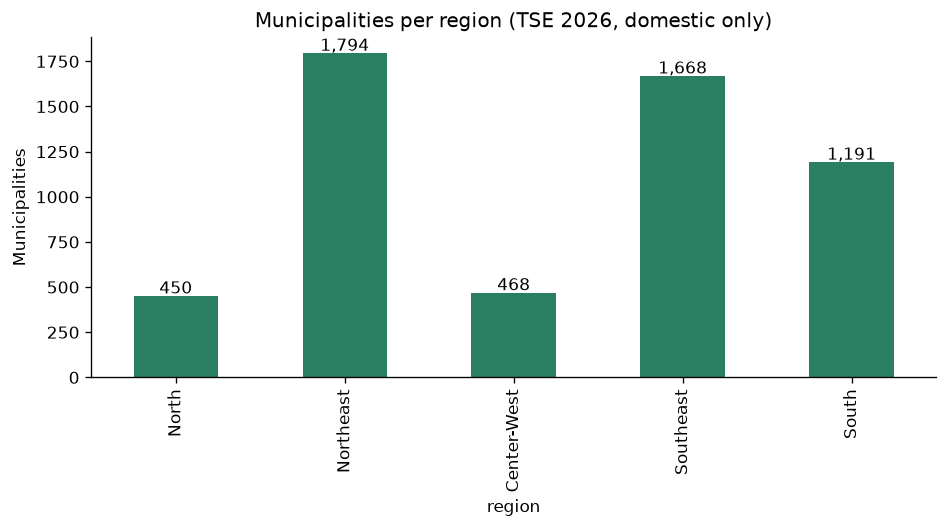

In [4]:
from pathlib import Path
import pandas as pd, matplotlib.pyplot as plt
# Find the repo root: works whether the notebook is run from notebooks/ or from the repo root.
def find_root():
    for cand in [Path(".."), Path("."), Path("/content/brazil-2026-elections")]:
        if (cand / "data" / "processed").exists():
            return cand
    return Path("..")
ROOT = find_root()
PROC = ROOT / "data" / "processed"
CHARTS = ROOT / "charts"
CHARTS.mkdir(exist_ok=True)
plt.rcParams["figure.dpi"] = 120
print("Data folder:", PROC.resolve())
# One chart for this chapter: how many municipalities does each region actually contain?
mun = pd.read_csv(PROC / "mun_2026.csv")
r1 = mun[(mun["NR_TURNO"] == 1) & (mun["SG_UF"] != "ZZ")]
counts = r1.groupby("region")["CD_MUNICIPIO"].nunique().reindex(
    ["North", "Northeast", "Center-West", "Southeast", "South"])
print(counts.to_string())
print(f"Domestic municipalities in round 1: {len(r1):,} (plus 186 overseas locations, ZZ)")
fig, ax = plt.subplots(figsize=(8, 4.5))
counts.plot(kind="bar", ax=ax, color="#2a7f62")
ax.set_title("Municipalities per region (TSE 2026, domestic only)")
ax.set_ylabel("Municipalities")
for i, v in enumerate(counts.values):
    ax.text(i, v + 15, f"{v:,}", ha="center")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout(); plt.savefig(CHARTS / "00_municipalities_by_region.png"); plt.show()

**Takeaway for Chapter 0.** The data are real, official, and checkable: the TSE files reproduce the headline result to the vote. The two traps (the duplicate `BRASIL` file and the leading-zero codes) are the kind of boring detail that decides whether a big analysis is right or quietly wrong, and they are documented here so anyone can re-do the build and get the same numbers.

Next: Chapter 1, where we shrink the whole election down to 100 voters and watch a comeback happen with no fraud at all.